# 01. Fictional Data Generation and Ground Truth

**Procurement Intelligence Platform** | Notebook 01 of 13

A documented simulator creates four years of SAP-like procurement data. Because we design the patterns, we can later check whether each model really finds them.

| | |
|---|---|
| **Inputs** | `src/p2p/config.py`, `src/p2p/generator/` |
| **Outputs** | `data/raw/*.csv` (14 SAP-like extracts), `data/ground_truth/` (hidden answers) |
| **Skills shown** | Simulation design, domain modelling, reproducibility |

## 1. Why simulate instead of using real data?

Real procurement data is confidential (supplier names, prices, employees), so it cannot be published. A simulator solves that and
gives three extra advantages:

1. **Known ground truth.** We decide the trend, the seasonality and the shocks, so we can test whether a model recovers them.
2. **Planted data-quality defects.** We know exactly how many errors exist, so the audit in notebook 02 can prove it caught all of them.
3. **The future is kept.** The simulator also records what happened *after* the extraction date. Models never see it, but we use it
   in notebook 12 to check lead-time predictions against reality.

The process structure (stages, approval levels, downpayments, delay categories, the foreign/local split) mirrors a real maintenance
procurement operation. Volumes, names and durations are invented.

## 2. Design of the simulator

The generator works in four layers, each with a known cause:

| Layer | What is simulated | Key mechanisms |
|---|---|---|
| Leading indicators | Fleet utilisation, FX rate, work orders | Seasonal utilisation, 55% devaluation in 2023, planned maintenance on a fixed 4 and 13-week schedule |
| Demand | Requisition lines from four drivers | **CM** breakdowns (rainy season, utilisation), **PM** parts ordered 2 to 3 weeks before planned work, **MRP restock** every second Tuesday, lumpy **projects** |
| Lifecycle | Every stage of every line | Buyer workload slows RFQs, MD approval above a value threshold, FX delays on foreign downpayments, supplier reliability, port congestion, inspection rejections, partial deliveries |
| Extraction | What SAP would export on 31 Dec 2025 | Events after the snapshot are unknown, plus planted data-quality defects |

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from p2p.viz.theme import use_matplotlib, BRAND, SERIES, ORIGIN_COLORS, STATUS, shade_shocks
use_matplotlib()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
from p2p.generator.export import write
import json, time

t0 = time.time()
gt = write()   # deterministic: the same seed always produces the same data
print(f"Generated in {time.time() - t0:.1f} s (seed {gt['seed']}, snapshot {gt['snapshot_date']})\n")
display(pd.Series(gt["row_counts"], name="rows").to_frame())

Generated in 6.9 s (seed 20251231, snapshot 2025-12-31)



,rows
purchase_requisitions,35078
rfqs,34670
purchase_orders,33312
po_approvals,30970
payments,44443
goods_receipts,35326
work_orders,17748
suppliers,60
materials,1500
equipment,206


**What we see.** Fourteen extracts with about 35,000 requisition lines, 33,000 PO lines, 35,000 goods-receipt documents and 44,000
payments. The simulation starts in June 2021 so that the backlog is already realistic when the analysis period starts in January 2022
(a cold start would show an empty backlog filling up, which no real company has).

## 3. Master data

In [3]:
raw = ROOT / "data" / "raw"
suppliers = pd.read_csv(raw / "suppliers.csv")
materials = pd.read_csv(raw / "materials.csv")
display(suppliers.sample(6, random_state=3))
print(suppliers.groupby("supplier_origin").agg(suppliers=("supplier_id", "count"),
      median_quoted_lead_time=("quoted_lead_time_days", "median"),
      share_requiring_downpayment=("downpayment_required", "mean")).round(2))

,supplier_id,supplier_name,supplier_origin,country,quoted_lead_time_days,downpayment_required,downpayment_pct,payment_terms_days
47,V10048,Yarrowby Hydraulics Ltd,Local,Domestic,15,False,0.000,30
18,V10019,Lumora Spares and Services,Foreign,South Africa,85,False,0.000,30
56,V10057,Kalhari Ship Spares Ltd,Local,Domestic,11,False,0.000,30
13,V10014,Callowind Energy Systems,Foreign,United Arab Emirates,98,True,0.300,45
37,V10038,Orinoco Ridge Electrical Ltd,Local,Domestic,13,False,0.000,60
23,V10024,Darnholm Engineering,Foreign,United Arab Emirates,59,True,0.400,45


                 suppliers  median_quoted_lead_time  share_requiring_downpayment
supplier_origin                                                                 
Foreign                 36                   82.000                        0.640
Local                   24                   19.000                        0.210


**What we see.** 36 foreign suppliers quote around 80 days of lead time and two thirds of them require a downpayment before they start
production. 24 local suppliers quote about 18 days and rarely ask for a downpayment.

**Why it matters.** The downpayment step links procurement to Finance. When Finance is slow, the supplier clock does not even start,
which is invisible in a classic "supplier lead time" report.

## 4. The demand we designed

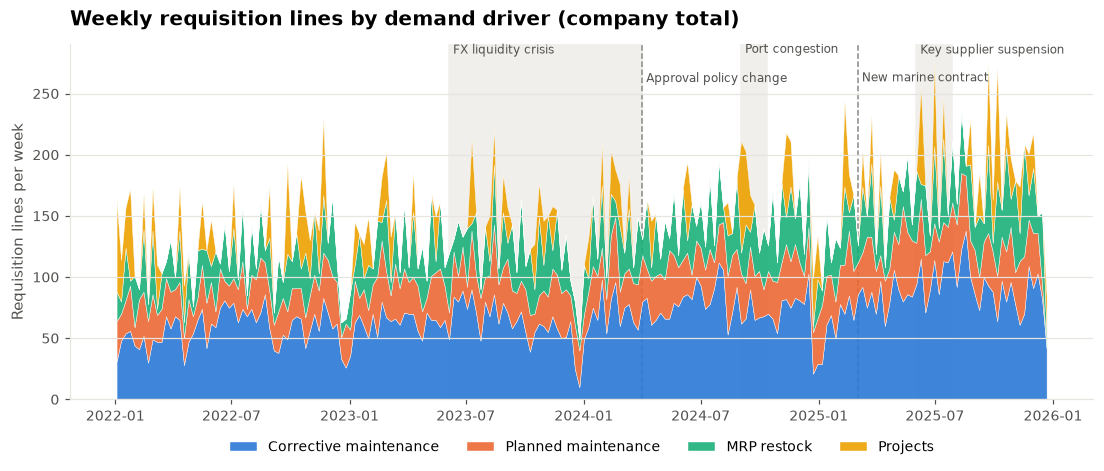

reason_code,CM,PM,PROJECT,RESTOCK
share,0.466,0.221,0.097,0.216


In [4]:
pr = pd.read_csv(raw / "purchase_requisitions.csv", parse_dates=["created_on"]).drop_duplicates(["pr_number", "pr_item"])
pr = pr[pr.created_on >= "2022-01-03"]
weekly = pr.groupby([pd.Grouper(key="created_on", freq="W-MON", label="left", closed="left"), "reason_code"]).size().unstack(fill_value=0)
weekly = weekly[weekly.index <= "2025-12-22"]   # the last week is incomplete at the extraction date

fig, ax = plt.subplots(figsize=(12, 4.2))
order = ["CM", "PM", "RESTOCK", "PROJECT"]
labels = {"CM": "Corrective maintenance", "PM": "Planned maintenance", "RESTOCK": "MRP restock", "PROJECT": "Projects"}
ax.stackplot(weekly.index, *[weekly[c] for c in order], labels=[labels[c] for c in order], colors=SERIES[:4], alpha=0.9, edgecolor="white", linewidth=0.3)
shade_shocks(ax)
ax.set_ylabel("Requisition lines per week"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4)
ax.set_title("Weekly requisition lines by demand driver (company total)")
plt.show()
display((weekly.sum() / weekly.sum().sum()).rename("share").to_frame().T)

**What we see.** Corrective maintenance is almost half of the demand and peaks every rainy season (June to September). The year-end
shutdown creates a sharp dip every December. Planned maintenance and restock are steadier, and projects arrive as spikes.

**Why it matters for modelling.** Three of the four drivers are partly predictable (season, maintenance schedule, MRP calendar). Projects
are not, so they set a floor on how accurate any model can be at section level. We expect the best models to separate the
predictable part from this noise rather than chase it.

## 5. The hidden answers (ground truth)

In [5]:
gt = json.loads((ROOT / "data" / "ground_truth" / "ground_truth.json").read_text())
print("Demand drivers:")
for k, v in gt["demand_drivers"].items():
    print(f"  {k:8s} {v}")
print("\nSeasonality:", gt["seasonality"])
print("MD approval threshold (USD):", gt["md_threshold_usd"])
print("Suspended supplier:", gt["suspended_supplier_id"])
planted = pd.Series(gt["planted_defects"], name="planted").to_frame()
display(planted)

Demand drivers:
  CM       Corrective maintenance: negative binomial, rises with rainy season (peak mid-July) and fleet utilisation
  PM       Planned maintenance: fixed 4-week and 13-week schedule, parts requested 14-21 days ahead (known future covariate)
  RESTOCK  MRP run every second Tuesday, +30% in the October-November budget push
  PROJECT  Lumpy bursts of 12-40 lines in about 3% of weeks

Seasonality: {'rainy_season_peak_doy': 198, 'shutdown': '18 Dec to 6 Jan at 45-75% activity', 'q4_restock_push': 1.3}
MD approval threshold (USD): {'before_policy': 5000.0, 'after_policy': 25000.0}
Suspended supplier: V10004


,planted
pr_section_messy_text,5207
pr_status_inconsistent,11
po_missing_supplier,171
po_zero_price,72
po_date_before_pr,69
po_orphan_without_pr,48
gr_over_delivery,117
gr_future_posting_date,6
gr_exact_duplicates,141
pr_exact_duplicates,105


These defects mirror what is found in real SAP extracts: free-text section names typed in different ways, duplicate documents, a PO
dated a year before its requisition, receipts posted in the year 2052, POs with no supplier or a zero price, and SAP status fields that
disagree with the documents. Notebook 02 must find every one of them.

## 6. Does it behave like a real procurement backlog?

In [6]:
from p2p.data import query
check = query("""
    select
        avg((supplier_origin = 'Foreign')::int) filter (where is_open and po_number is not null) as foreign_share_of_open_po_lines,
        median(pr_to_receipt_days) filter (where supplier_origin = 'Foreign')                  as foreign_pr_to_receipt_p50_days,
        median(pr_to_receipt_days) filter (where supplier_origin = 'Local')                    as local_pr_to_receipt_p50_days,
        avg((reason_code = 'CM')::int)                                                         as corrective_share
    from marts.fct_requisition_line where pr_created_on >= '2022-01-03'
""").T.rename(columns={0: "value"})
display(check)

,value
foreign_share_of_open_po_lines,0.824
foreign_pr_to_receipt_p50_days,130.000
local_pr_to_receipt_p50_days,39.000
corrective_share,0.465


**What we see.** About 80% of the open PO lines are with foreign suppliers, although foreign suppliers receive less than half of all
POs. Nobody forced that number: foreign lines stay open three times longer, so they accumulate in the backlog. The same ratio appears
in real maintenance procurement backlogs, which is a good sign that the lifecycle mechanics are realistic.

## 7. Summary

* The dataset is **reproducible** (fixed seed, about 8 seconds to regenerate) and **documented** (every pattern has a stated cause).
* We know the right answers: drivers, shocks and every planted defect.
* The raw files look like a real SAP export: text columns, mixed date formats, defects included.

**Next:** notebook 02 ingests the raw extracts and audits their quality before anyone trusts a number.